# Data-Quality Validation

**Goal:** check a dataset against clear, documented rules *before* it is used for analysis or reporting, and produce a scorecard and a list of records to fix.

Trustworthy analysis depends on data that is complete, unique, valid, consistent and timely. This notebook shows a lightweight, repeatable way to measure those five dimensions with Python and pandas.

| Dimension | Question it answers | Example rule here |
|---|---|---|
| **Completeness** | Is anything missing? | GDP is not null |
| **Uniqueness** | Is any record repeated? | One row per country and quarter |
| **Validity** | Do values follow the rules? | Unemployment is between 0 and 100% |
| **Consistency** | Do related fields agree? | GDP per capita = GDP ÷ population |
| **Timeliness** | Are dates realistic? | Last-updated date is not in the future |

> **Data:** a *synthetic* quarterly economic-indicators dataset (10 countries, 2020–2025). Issues were injected on purpose by [`data/generate_sample_data.py`](../data/generate_sample_data.py). Values are not real statistics.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from dq import checks

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

AS_OF = "2026-11-01"   # reference date for timeliness checks (fixed so results are reproducible)
QUALITY_GATE = 0.95     # share of records that must be issue-free for the data to be accepted

## 2. Load the data

In [2]:
df = pd.read_csv(ROOT / "data" / "economic_indicators.csv")
print(f"{len(df):,} rows × {df.shape[1]} columns")
df.head()

245 rows × 11 columns


,record_id,country_code,country_name,quarter,gdp_usd_bn,population_m,gdp_per_capita_usd,inflation_rate_pct,unemployment_rate_pct,last_updated,source
0,1,GHA,Ghana,2020-Q1,19.06,33.5,568.96,1.84,9.25,2020-05-02,Central Bank
1,2,GHA,Ghana,2020-Q2,18.74,33.6,557.74,0.79,7.38,2020-08-20,Central Bank
2,3,GHA,Ghana,2020-Q3,19.22,33.7,570.33,2.59,9.64,2020-11-04,Central Bank
3,4,GHA,Ghana,2020-Q4,19.35,33.8,572.49,10.51,8.40,2021-02-12,National Statistics Office
4,5,GHA,Ghana,2021-Q1,19.53,33.9,576.11,2.16,9.64,2021-05-08,Central Bank


## 3. Quick profile

A first look at types and missing values helps decide which rules to write.

In [3]:
profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "nulls": df.isna().sum(),
    "null_pct": (df.isna().mean() * 100).round(1),
    "distinct": df.nunique(),
})
profile

,dtype,non_null,nulls,null_pct,distinct
record_id,int64,245,0,0.0,245
country_code,str,245,0,0.0,11
country_name,str,245,0,0.0,10
quarter,str,245,0,0.0,25
gdp_usd_bn,float64,237,8,3.3,229
population_m,float64,245,0,0.0,240
gdp_per_capita_usd,float64,245,0,0.0,239
inflation_rate_pct,float64,245,0,0.0,221
unemployment_rate_pct,float64,240,5,2.0,208
last_updated,str,245,0,0.0,208


## 4. Define the rules

Rules are written as data, so they are easy to review with business owners and to extend. The reference list of country codes plays the role of governed **reference data** (in practice this would come from a catalog such as Collibra or a master-data table).

In [4]:
VALID_COUNTRIES = {
    "GHA": "Ghana", "NGA": "Nigeria", "KEN": "Kenya", "ZAF": "South Africa",
    "USA": "United States", "GBR": "United Kingdom", "DEU": "Germany",
    "IND": "India", "BRA": "Brazil", "CAN": "Canada",
}

def per_capita_matches(d, tolerance=0.01):
    expected = d["gdp_usd_bn"] * 1e9 / (d["population_m"] * 1e6)
    return (d["gdp_per_capita_usd"] - expected).abs() <= tolerance * expected.abs()

def name_matches_code(d):
    return d["country_code"].map(VALID_COUNTRIES) == d["country_name"]

rules = [
    # Completeness
    lambda d: checks.not_null(d, "country_code"),
    lambda d: checks.not_null(d, "gdp_usd_bn"),
    lambda d: checks.not_null(d, "population_m"),
    lambda d: checks.not_null(d, "unemployment_rate_pct"),
    lambda d: checks.not_null(d, "source"),
    # Uniqueness
    lambda d: checks.unique(d, ["country_code", "quarter"]),
    # Validity
    lambda d: checks.allowed_values(d, "country_code", VALID_COUNTRIES),
    lambda d: checks.matches_pattern(d, "quarter", r"\d{4}-Q[1-4]", "YYYY-Q1..Q4"),
    lambda d: checks.in_range(d, "gdp_usd_bn", min_value=0),
    lambda d: checks.in_range(d, "population_m", min_value=0),
    lambda d: checks.in_range(d, "unemployment_rate_pct", 0, 100),
    lambda d: checks.in_range(d, "inflation_rate_pct", -50, 1000),
    lambda d: checks.parses_as_date(d, "last_updated"),
    # Consistency
    lambda d: checks.consistent(d, "gdp_per_capita_usd = GDP ÷ population (±1%)",
                                ["gdp_usd_bn", "population_m", "gdp_per_capita_usd"], per_capita_matches),
    lambda d: checks.consistent(d, "country_name matches country_code",
                                ["country_code", "country_name"], name_matches_code),
    # Timeliness
    lambda d: checks.not_in_future(d, "last_updated", AS_OF),
]
print(f"{len(rules)} rules defined")

16 rules defined


## 5. Run the checks and build the scorecard

In [5]:
results = [rule(df) for rule in rules]
card = checks.scorecard(results)
card.style.format({"pass_rate": "{:.1%}"}).map(
    lambda s: "color: #b42318; font-weight: 600" if s == "FAIL" else "color: #067647", subset=["status"]
)

,dimension,rule,columns,rows_checked,rows_failed,pass_rate,status
0,Completeness,country_code is not null,country_code,245,0,100.0%,PASS
1,Completeness,gdp_usd_bn is not null,gdp_usd_bn,245,8,96.7%,FAIL
2,Completeness,population_m is not null,population_m,245,0,100.0%,PASS
3,Completeness,unemployment_rate_pct is not null,unemployment_rate_pct,245,5,98.0%,FAIL
4,Completeness,source is not null,source,245,3,98.8%,FAIL
5,Uniqueness,"(country_code, quarter) is unique","country_code, quarter",245,5,98.0%,FAIL
6,Validity,country_code in reference list,country_code,245,4,98.4%,FAIL
7,Validity,quarter format is YYYY-Q1..Q4,quarter,245,4,98.4%,FAIL
8,Validity,gdp_usd_bn >= 0,gdp_usd_bn,245,5,98.0%,FAIL
9,Validity,population_m >= 0,population_m,245,0,100.0%,PASS


### Score by dimension

In [6]:
dims = checks.dimension_scores(results)
dims.style.format({"pass_rate": "{:.1%}"})

,dimension,rules,rules_failed,pass_rate
0,Consistency,2,2,97.4%
1,Uniqueness,1,1,98.0%
2,Completeness,5,3,98.7%
3,Timeliness,1,1,98.8%
4,Validity,7,5,98.8%


### Where are the problems?

Records failing each rule, largest first. Rules that passed are left out.

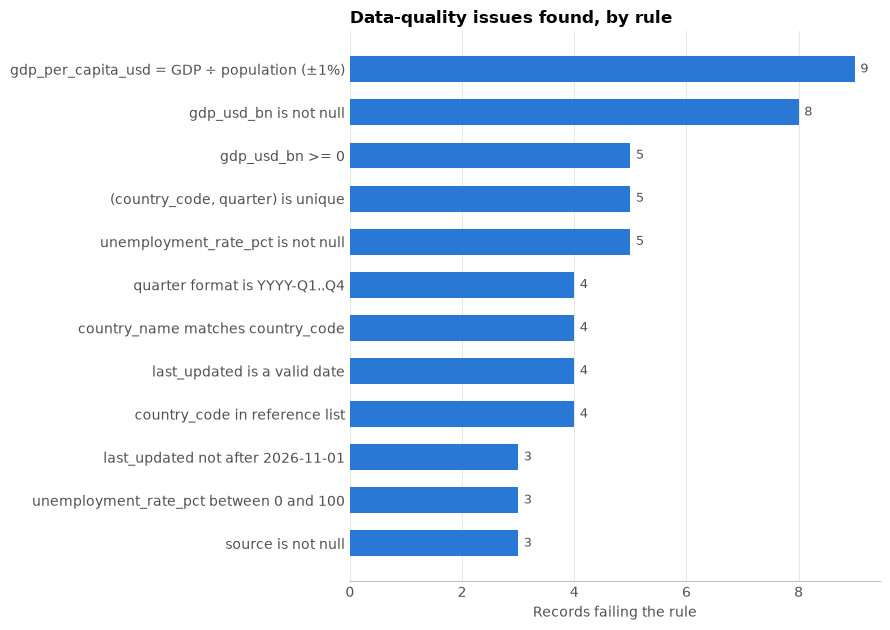

In [7]:
failed = card[card.rows_failed > 0].sort_values("rows_failed")

fig, ax = plt.subplots(figsize=(9, 0.45 * len(failed) + 1))
bars = ax.barh(failed["rule"], failed["rows_failed"], color="#2a78d6", height=0.6)
ax.bar_label(bars, padding=4, color="#52514e", fontsize=9)
ax.set_xlabel("Records failing the rule", color="#52514e")
ax.set_title("Data-quality issues found, by rule", loc="left", fontsize=12, fontweight="bold")
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors="#52514e", length=0)
ax.xaxis.grid(True, color="#e9e8e4")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 6. Records that need fixing

Each failing record appears once, with every rule it broke. This is the list a data steward would work through.

In [8]:
issues = checks.failing_rows(df, results)
print(f"{len(issues)} of {len(df)} records have at least one issue")
issues.head(15)

44 of 245 records have at least one issue


,issues,record_id,country_code,country_name,quarter,gdp_usd_bn,population_m,gdp_per_capita_usd,inflation_rate_pct,unemployment_rate_pct,last_updated,source
11,unemployment_rate_pct is not null,12,GHA,Ghana,2022-Q4,20.28,34.61,585.96,6.87,NaN,2023-02-18,National Statistics Office
13,unemployment_rate_pct is not null,14,GHA,Ghana,2023-Q2,20.21,34.81,580.58,4.72,NaN,2023-08-14,Central Bank
14,country_code in reference list; country_name m...,15,XXX,Ghana,2023-Q3,20.54,34.91,588.37,11.98,4.40,2023-11-18,National Statistics Office
17,last_updated not after 2026-11-01,18,GHA,Ghana,2024-Q2,21.10,35.21,599.26,5.23,3.17,2031-01-01,National Statistics Office
33,gdp_usd_bn is not null,34,NGA,Nigeria,2022-Q2,NaN,229.02,544.01,5.11,2.59,2022-08-11,National Statistics Office
36,quarter format is YYYY-Q1..Q4,37,NGA,Nigeria,2023Q5,125.00,231.03,541.06,4.34,5.16,2023-05-08,National Statistics Office
43,gdp_usd_bn is not null,44,NGA,Nigeria,2024-Q4,NaN,235.71,553.05,1.10,3.17,2025-02-03,Central Bank
67,unemployment_rate_pct between 0 and 100,68,KEN,Kenya,2024-Q4,30.68,58.13,527.78,7.41,120.00,2025-02-21,Central Bank
68,gdp_usd_bn >= 0; gdp_per_capita_usd = GDP ÷ po...,69,KEN,Kenya,2025-Q1,-30.60,58.30,524.87,7.27,6.71,2025-05-06,National Statistics Office
75,gdp_per_capita_usd = GDP ÷ population (±1%),76,ZAF,South Africa,2020-Q4,96.99,60.54,16020.80,4.51,1.73,2021-02-03,National Statistics Office


## 7. Quality gate

A simple pass/fail decision that a pipeline can use to stop bad data from flowing downstream.

In [9]:
clean_share = 1 - len(issues) / len(df)
verdict = "PASSED ✅" if clean_share >= QUALITY_GATE else "FAILED ❌"
print(f"Issue-free records: {clean_share:.1%}  (gate: {QUALITY_GATE:.0%})  →  {verdict}")

Issue-free records: 82.0%  (gate: 95%)  →  FAILED ❌


## 8. Export the reports

Saved to `reports/` so the results can be shared, tracked over time, or loaded into a dashboard.

In [10]:
reports = ROOT / "reports"
reports.mkdir(exist_ok=True)
card.to_csv(reports / "scorecard.csv", index=False)
issues.to_csv(reports / "failing_records.csv", index=False)
print("Saved:", *(p.name for p in sorted(reports.glob("*.csv"))), sep="\n  ")

Saved:
  failing_records.csv
  scorecard.csv


## 9. Takeaways and next steps

- **Rules as data** make quality expectations visible and reviewable by business owners, not hidden in code.
- **Dimension scores** give a quick health view, while the **failing-records list** tells data stewards exactly what to fix.
- A **quality gate** turns the checks into a control that can run in a pipeline before data is published.

**Ideas to extend this:**
- Run the same rules on a schedule in Databricks and track scores over time.
- Load rules and reference data from a governance catalog (for example, Collibra) instead of hard-coding them.
- Record which source system each failure came from, to support data lineage and root-cause analysis.
- Add freshness rules per source with agreed service levels.